# Sniffing the Belts: Investigating Potential Flux Levels At High Magnetic Latitude In A Low-Medium Earth Orbit

This notebook walks through fitting the 75th Percentile flux measurments from the HEP-L instrument on board the ARASE Spacecraft, for full details please see Weston et al. 2026 (DOI to be Issued)


In [87]:
## Install Required Packages ##
!pip install lmfit
!pip install tqdm

In [88]:
## Import Packages ##
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lmfit import Model
from tqdm import tqdm
from matplotlib.patches import Patch
from matplotlib import colors
from matplotlib import colormaps
import matplotlib.patches as patches

In [89]:
## Import Data ##
All_times=pd.read_csv('/content/75_all_Kp.csv')
energy_list=list(All_times['Unnamed: 0'])

All_times=All_times.iloc[:,1:]
mlat=np.array(All_times.columns).astype('float')
Low_Kp=pd.read_csv('/content/75_low_Kp.csv').iloc[:,1:]
Medium_Kp=pd.read_csv('/content/75_med_Kp.csv').iloc[:,1:]
High_Kp=pd.read_csv('/content/75_high_Kp.csv').iloc[:,1:]

Initial_Phase=pd.read_csv('/content/75_initial_phase.csv').iloc[:,1:]
Main_Phase=pd.read_csv('/content/75_main_phase.csv').iloc[:,1:]
Recovery_Phase=pd.read_csv('/content/75_recovery_phase.csv').iloc[:,1:]

Low_extrapolated=pd.DataFrame()
Medium_extrapolated=pd.DataFrame()
High_extrapolated=pd.DataFrame()
extrapolated_mlats=np.linspace(-60,60,25)


In [90]:
def von_mises(x, A, w, phi, C):
    return np.exp(A * np.cos(w * x + phi) + C)

def von_mises_log(x, A, w, phi, C):
    return A * np.cos(w * x + phi) + C

Fitting and Extrapolating Kp Levels

In [91]:
## All Kp Levels ##
All_extrapolated=pd.DataFrame()

for energy in tqdm(range(0,len(energy_list))):

  current_flux=All_times.iloc[energy,:]
  log_y = np.log(current_flux)

  A0 = (log_y.max() - log_y.min()) / 2
  C0 = (log_y.max() + log_y.min()) / 2
  peak_idx = np.argmax(log_y)

  model  = Model(von_mises_log)
  params = model.make_params(A=A0, w=0.08, phi=0.0, C=C0)
  params['A'].min   =  0
  params['w'].min   =  0
  params['phi'].min = -np.pi
  params['phi'].max =  np.pi
  params['C'].min=1

  weights = 1.0 / (np.abs(np.gradient(log_y)) + 0.1)
  weights /= weights.sum()  # normalise
  result = model.fit(log_y, params, x=mlat,reduce_fcn='cauchy',weights=weights)
  A   = result.params['A'].value
  w   = result.params['w'].value
  phi = result.params['phi'].value
  C   = result.params['C'].value
  K   = np.exp(C)

  temp=np.array([von_mises(-60, A, w, phi, C),von_mises(-55, A, w, phi, C),von_mises(-50, A, w, phi, C),von_mises(-45, A, w, phi, C)]+list(current_flux)+[von_mises(45, A, w, phi, C),von_mises(50, A, w, phi, C),von_mises(55, A, w, phi, C),von_mises(60, A, w, phi, C)])


  temp_df=pd.DataFrame(temp.reshape(1,25),index=[energy_list[energy]],columns=extrapolated_mlats)
  All_extrapolated=pd.concat((All_extrapolated,temp_df),axis=0)




  0%|          | 0/14 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/lmfit/model.py:1127: UserWarning: The keyword argument reduce_fcn does not match any arguments of the model function. It will be ignored.
  warnings.warn(f"The keyword argument {name} does not " +
100%|██████████| 14/14 [00:00<00:00, 204.77it/s]


In [92]:
## Low Kp Levels ##
Low_extrapolated=pd.DataFrame()

for energy in tqdm(range(0,len(energy_list))):

  current_flux=Low_Kp.iloc[energy,:]
  log_y = np.log(current_flux)

  A0 = (log_y.max() - log_y.min()) / 2
  C0 = (log_y.max() + log_y.min()) / 2
  peak_idx = np.argmax(log_y)

  model  = Model(von_mises_log)
  params = model.make_params(A=A0, w=0.08, phi=0.0, C=C0)
  params['A'].min   =  0
  params['w'].min   =  0
  params['phi'].min = -np.pi
  params['phi'].max =  np.pi
  params['C'].min=1

  weights = 1.0 / (np.abs(np.gradient(log_y)) + 0.1)
  weights /= weights.sum()  # normalise
  result = model.fit(log_y, params, x=mlat,reduce_fcn='cauchy',weights=weights)
  A   = result.params['A'].value
  w   = result.params['w'].value
  phi = result.params['phi'].value
  C   = result.params['C'].value
  K   = np.exp(C)

  temp=np.array([von_mises(-60, A, w, phi, C),von_mises(-55, A, w, phi, C),von_mises(-50, A, w, phi, C),von_mises(-45, A, w, phi, C)]+list(current_flux)+[von_mises(45, A, w, phi, C),von_mises(50, A, w, phi, C),von_mises(55, A, w, phi, C),von_mises(60, A, w, phi, C)])


  temp_df=pd.DataFrame(temp.reshape(1,25),index=[energy_list[energy]],columns=extrapolated_mlats)
  Low_extrapolated=pd.concat((Low_extrapolated,temp_df),axis=0)



  0%|          | 0/14 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/lmfit/model.py:1127: UserWarning: The keyword argument reduce_fcn does not match any arguments of the model function. It will be ignored.
  warnings.warn(f"The keyword argument {name} does not " +
100%|██████████| 14/14 [00:00<00:00, 187.51it/s]


In [93]:
## Medium Kp Levels ##
Med_extrapolated=pd.DataFrame()

for energy in tqdm(range(0,len(energy_list))):

  current_flux=Medium_Kp.iloc[energy,:]
  log_y = np.log(current_flux)

  A0 = (log_y.max() - log_y.min()) / 2
  C0 = (log_y.max() + log_y.min()) / 2
  peak_idx = np.argmax(log_y)

  model  = Model(von_mises_log)
  params = model.make_params(A=A0, w=0.08, phi=0.0, C=C0)
  params['A'].min   =  0
  params['w'].min   =  0
  params['phi'].min = -np.pi
  params['phi'].max =  np.pi
  params['C'].min=1

  weights = 1.0 / (np.abs(np.gradient(log_y)) + 0.1)
  weights /= weights.sum()  # normalise
  result = model.fit(log_y, params, x=mlat,reduce_fcn='cauchy',weights=weights)
  A   = result.params['A'].value
  w   = result.params['w'].value
  phi = result.params['phi'].value
  C   = result.params['C'].value
  K   = np.exp(C)

  temp=np.array([von_mises(-60, A, w, phi, C),von_mises(-55, A, w, phi, C),von_mises(-50, A, w, phi, C),von_mises(-45, A, w, phi, C)]+list(current_flux)+[von_mises(45, A, w, phi, C),von_mises(50, A, w, phi, C),von_mises(55, A, w, phi, C),von_mises(60, A, w, phi, C)])


  temp_df=pd.DataFrame(temp.reshape(1,25),index=[energy_list[energy]],columns=extrapolated_mlats)
  Med_extrapolated=pd.concat((Med_extrapolated,temp_df),axis=0)

  0%|          | 0/14 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/lmfit/model.py:1127: UserWarning: The keyword argument reduce_fcn does not match any arguments of the model function. It will be ignored.
  warnings.warn(f"The keyword argument {name} does not " +
100%|██████████| 14/14 [00:00<00:00, 169.74it/s]


In [94]:
## High Kp Levels ##
High_extrapolated=pd.DataFrame()

for energy in tqdm(range(0,len(energy_list))):

  current_flux=Medium_Kp.iloc[energy,:]
  log_y = np.log(current_flux)

  A0 = (log_y.max() - log_y.min()) / 2
  C0 = (log_y.max() + log_y.min()) / 2
  peak_idx = np.argmax(log_y)

  model  = Model(von_mises_log)
  params = model.make_params(A=A0, w=0.08, phi=0.0, C=C0)
  params['A'].min   =  0
  params['w'].min   =  0
  params['phi'].min = -np.pi
  params['phi'].max =  np.pi
  params['C'].min=1

  weights = 1.0 / (np.abs(np.gradient(log_y)) + 0.1)
  weights /= weights.sum()  # normalise
  result = model.fit(log_y, params, x=mlat,reduce_fcn='cauchy',weights=weights)
  A   = result.params['A'].value
  w   = result.params['w'].value
  phi = result.params['phi'].value
  C   = result.params['C'].value
  K   = np.exp(C)

  temp=np.array([von_mises(-60, A, w, phi, C),von_mises(-55, A, w, phi, C),von_mises(-50, A, w, phi, C),von_mises(-45, A, w, phi, C)]+list(current_flux)+[von_mises(45, A, w, phi, C),von_mises(50, A, w, phi, C),von_mises(55, A, w, phi, C),von_mises(60, A, w, phi, C)])


  temp_df=pd.DataFrame(temp.reshape(1,25),index=[energy_list[energy]],columns=extrapolated_mlats)
  High_extrapolated=pd.concat((High_extrapolated,temp_df),axis=0)

  0%|          | 0/14 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/lmfit/model.py:1127: UserWarning: The keyword argument reduce_fcn does not match any arguments of the model function. It will be ignored.
  warnings.warn(f"The keyword argument {name} does not " +
100%|██████████| 14/14 [00:00<00:00, 53.39it/s]


Plotting The Resulting Extrapolations


Text(0.5, 0.97, '$75^{th}$ Percentile Electron Flux, With Extrapolated Values Up To MLAT=$\\pm$60 ')

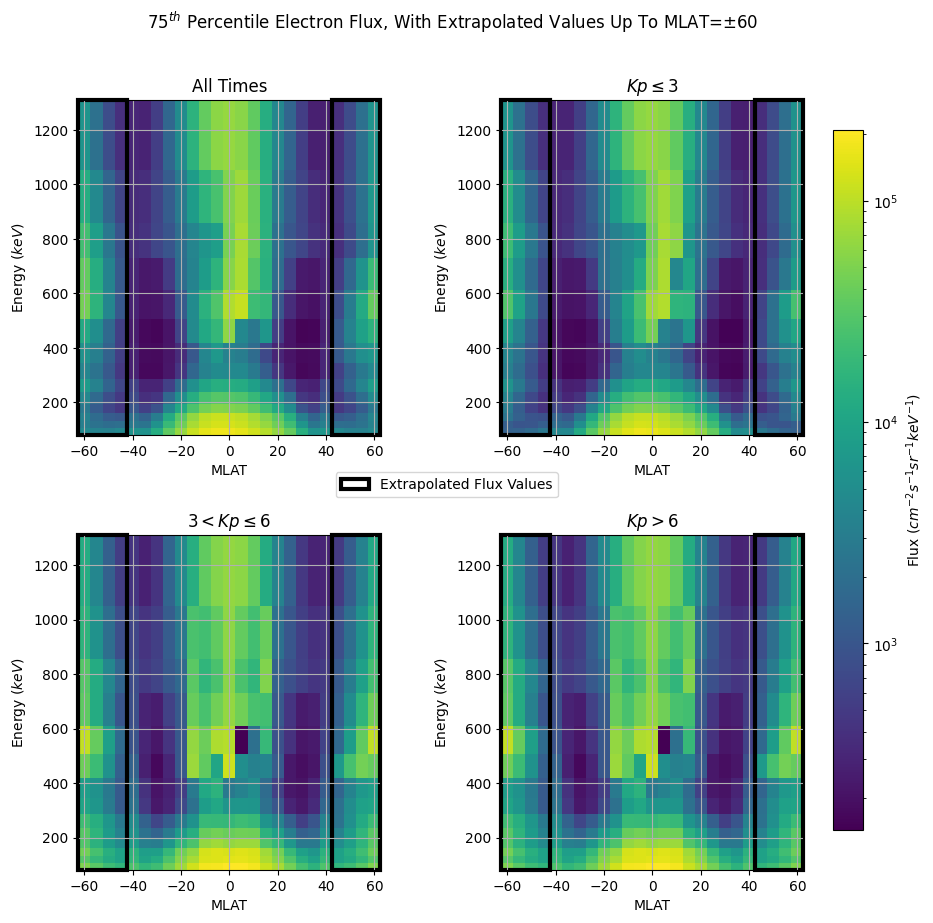

In [95]:
mins=[np.nanmin(All_extrapolated),np.nanmin(Low_extrapolated),np.nanmin(Med_extrapolated),np.nanmin(High_extrapolated)]
maxs=[np.nanmax(All_extrapolated),np.nanmax(Low_extrapolated),np.nanmax(Med_extrapolated),np.nanmax(High_extrapolated)]
cmap=colormaps['viridis']
cmap.set_under('white')
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(10,10))
plt.subplots_adjust(wspace=0.4,hspace=0.3)

im=axs[0,0].pcolormesh(extrapolated_mlats,energy_list,All_extrapolated,cmap=cmap,norm=colors.LogNorm(vmin=np.nanmin(mins), vmax=np.nanmax(maxs)))
im=axs[0,1].pcolormesh(extrapolated_mlats,energy_list,Low_extrapolated,cmap=cmap,norm=colors.LogNorm(vmin=np.nanmin(mins), vmax=np.nanmax(maxs)))
im=axs[1,0].pcolormesh(extrapolated_mlats,energy_list,Med_extrapolated,cmap=cmap,norm=colors.LogNorm(vmin=np.nanmin(mins), vmax=np.nanmax(maxs)))
im=axs[1,1].pcolormesh(extrapolated_mlats,energy_list,High_extrapolated,cmap=cmap,norm=colors.LogNorm(vmin=np.nanmin(mins), vmax=np.nanmax(maxs)))

axs[0,0].set_title('All Times')
axs[0,1].set_title(r'$Kp\leq3$')
axs[1,0].set_title(r'$3<Kp\leq6$')
axs[1,1].set_title('$Kp>6$')

for ax in fig.axes:
    ax.set_xlabel('MLAT')
    ax.set_ylabel(r'Energy ($keV$)')
    ax.grid()
    left_rect = patches.Rectangle(
        (0, 0),      # bottom-left corner in axes coords
        0.16,         # width in axes coords
        1,        # height in axes coords
        linewidth=3,
        edgecolor='black',
        facecolor='none',  # transparent fill
        transform=ax.transAxes,
        clip_on=False      # allows drawing outside axes if needed
        )

    right_rect = patches.Rectangle(
        (1-0.16, 0),      # bottom-left corner in axes coords
        0.16,         # width in axes coords
        1,        # height in axes coords
        linewidth=3,
        edgecolor='black',
        facecolor='none',  # transparent fill
        transform=ax.transAxes,
        clip_on=False      # allows drawing outside axes if needed
        )
    ax.set_ylim(ax.get_ylim()[0],ax.get_ylim()[1])
    ax.add_patch(left_rect)
    ax.add_patch(right_rect)
patch=[patches.Rectangle(
        (1-0.16, 0),      # bottom-left corner in axes coords
        0.16,         # width in axes coords
        1,        # height in axes coords
        linewidth=3,
        edgecolor='black',
        facecolor='none',  # transparent fill
        label='Extrapolated Flux Values')]
axs[1,1].legend(loc='center',handles=patch,bbox_to_anchor=(-0.18,1.15))

fig.subplots_adjust(right=0.85)
cbar_ax = fig.add_axes([0.88, 0.15, 0.03, 0.7])  # [left, bottom, width, height]
fig.colorbar(im, cax=cbar_ax,label=r'Flux ($cm^{-2}s^{-1}sr^{-1}keV^{-1}$)')
fig.suptitle(r'$75^{th}$ Percentile Electron Flux, With Extrapolated Values Up To MLAT=$\pm$60 ',y=0.97)

Fitting and Extrapolating Storm Phases


In [96]:
## All Kp Levels ##
All_extrapolated=pd.DataFrame()

for energy in tqdm(range(0,len(energy_list))):

  current_flux=All_times.iloc[energy,:]
  log_y = np.log(current_flux)

  A0 = (log_y.max() - log_y.min()) / 2
  C0 = (log_y.max() + log_y.min()) / 2
  peak_idx = np.argmax(log_y)

  model  = Model(von_mises_log)
  params = model.make_params(A=A0, w=0.08, phi=0.0, C=C0)
  params['A'].min   =  0
  params['w'].min   =  0
  params['phi'].min = -np.pi
  params['phi'].max =  np.pi
  params['C'].min=1

  weights = 1.0 / (np.abs(np.gradient(log_y)) + 0.1)
  weights /= weights.sum()  # normalise
  result = model.fit(log_y, params, x=mlat,reduce_fcn='cauchy',weights=weights)
  A   = result.params['A'].value
  w   = result.params['w'].value
  phi = result.params['phi'].value
  C   = result.params['C'].value
  K   = np.exp(C)

  temp=np.array([von_mises(-60, A, w, phi, C),von_mises(-55, A, w, phi, C),von_mises(-50, A, w, phi, C),von_mises(-45, A, w, phi, C)]+list(current_flux)+[von_mises(45, A, w, phi, C),von_mises(50, A, w, phi, C),von_mises(55, A, w, phi, C),von_mises(60, A, w, phi, C)])


  temp_df=pd.DataFrame(temp.reshape(1,25),index=[energy_list[energy]],columns=extrapolated_mlats)
  All_extrapolated=pd.concat((All_extrapolated,temp_df),axis=0)




  0%|          | 0/14 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/lmfit/model.py:1127: UserWarning: The keyword argument reduce_fcn does not match any arguments of the model function. It will be ignored.
  warnings.warn(f"The keyword argument {name} does not " +
100%|██████████| 14/14 [00:00<00:00, 102.14it/s]


In [97]:
## Initial Phase ##
Initial_extrapolated=pd.DataFrame()

for energy in tqdm(range(0,len(energy_list))):

  current_flux=Initial_Phase.iloc[energy,:]
  log_y = np.log(current_flux)

  A0 = (log_y.max() - log_y.min()) / 2
  C0 = (log_y.max() + log_y.min()) / 2
  peak_idx = np.argmax(log_y)

  model  = Model(von_mises_log)
  params = model.make_params(A=A0, w=0.08, phi=0.0, C=C0)
  params['A'].min   =  0
  params['w'].min   =  0
  params['phi'].min = -np.pi
  params['phi'].max =  np.pi
  params['C'].min=1

  weights = 1.0 / (np.abs(np.gradient(log_y)) + 0.1)
  weights /= weights.sum()  # normalise
  result = model.fit(log_y, params, x=mlat,reduce_fcn='cauchy',weights=weights)
  A   = result.params['A'].value
  w   = result.params['w'].value
  phi = result.params['phi'].value
  C   = result.params['C'].value
  K   = np.exp(C)

  temp=np.array([von_mises(-60, A, w, phi, C),von_mises(-55, A, w, phi, C),von_mises(-50, A, w, phi, C),von_mises(-45, A, w, phi, C)]+list(current_flux)+[von_mises(45, A, w, phi, C),von_mises(50, A, w, phi, C),von_mises(55, A, w, phi, C),von_mises(60, A, w, phi, C)])


  temp_df=pd.DataFrame(temp.reshape(1,25),index=[energy_list[energy]],columns=extrapolated_mlats)
  Initial_extrapolated=pd.concat((Initial_extrapolated,temp_df),axis=0)




  0%|          | 0/14 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/lmfit/model.py:1127: UserWarning: The keyword argument reduce_fcn does not match any arguments of the model function. It will be ignored.
  warnings.warn(f"The keyword argument {name} does not " +
100%|██████████| 14/14 [00:00<00:00, 140.85it/s]


In [98]:
## Main Phase ##
Main_extrapolated=pd.DataFrame()

for energy in tqdm(range(0,len(energy_list))):

  current_flux=Main_Phase.iloc[energy,:]
  log_y = np.log(current_flux)

  A0 = (log_y.max() - log_y.min()) / 2
  C0 = (log_y.max() + log_y.min()) / 2
  peak_idx = np.argmax(log_y)

  model  = Model(von_mises_log)
  params = model.make_params(A=A0, w=0.08, phi=0.0, C=C0)
  params['A'].min   =  0
  params['w'].min   =  0
  params['phi'].min = -np.pi
  params['phi'].max =  np.pi
  params['C'].min=1

  weights = 1.0 / (np.abs(np.gradient(log_y)) + 0.1)
  weights /= weights.sum()  # normalise
  result = model.fit(log_y, params, x=mlat,reduce_fcn='cauchy',weights=weights)
  A   = result.params['A'].value
  w   = result.params['w'].value
  phi = result.params['phi'].value
  C   = result.params['C'].value
  K   = np.exp(C)

  temp=np.array([von_mises(-60, A, w, phi, C),von_mises(-55, A, w, phi, C),von_mises(-50, A, w, phi, C),von_mises(-45, A, w, phi, C)]+list(current_flux)+[von_mises(45, A, w, phi, C),von_mises(50, A, w, phi, C),von_mises(55, A, w, phi, C),von_mises(60, A, w, phi, C)])


  temp_df=pd.DataFrame(temp.reshape(1,25),index=[energy_list[energy]],columns=extrapolated_mlats)
  Main_extrapolated=pd.concat((Main_extrapolated,temp_df),axis=0)




  0%|          | 0/14 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/lmfit/model.py:1127: UserWarning: The keyword argument reduce_fcn does not match any arguments of the model function. It will be ignored.
  warnings.warn(f"The keyword argument {name} does not " +
100%|██████████| 14/14 [00:00<00:00, 159.67it/s]


In [99]:
## Recovery Phase ##
Recovery_extrapolated=pd.DataFrame()

for energy in tqdm(range(0,len(energy_list))):

  current_flux=Recovery_Phase.iloc[energy,:]
  log_y = np.log(current_flux)

  A0 = (log_y.max() - log_y.min()) / 2
  C0 = (log_y.max() + log_y.min()) / 2
  peak_idx = np.argmax(log_y)

  model  = Model(von_mises_log)
  params = model.make_params(A=A0, w=0.08, phi=0.0, C=C0)
  params['A'].min   =  0
  params['w'].min   =  0
  params['phi'].min = -np.pi
  params['phi'].max =  np.pi
  params['C'].min=1

  weights = 1.0 / (np.abs(np.gradient(log_y)) + 0.1)
  weights /= weights.sum()  # normalise
  result = model.fit(log_y, params, x=mlat,reduce_fcn='cauchy',weights=weights)
  A   = result.params['A'].value
  w   = result.params['w'].value
  phi = result.params['phi'].value
  C   = result.params['C'].value
  K   = np.exp(C)

  temp=np.array([von_mises(-60, A, w, phi, C),von_mises(-55, A, w, phi, C),von_mises(-50, A, w, phi, C),von_mises(-45, A, w, phi, C)]+list(current_flux)+[von_mises(45, A, w, phi, C),von_mises(50, A, w, phi, C),von_mises(55, A, w, phi, C),von_mises(60, A, w, phi, C)])


  temp_df=pd.DataFrame(temp.reshape(1,25),index=[energy_list[energy]],columns=extrapolated_mlats)
  Recovery_extrapolated=pd.concat((Recovery_extrapolated,temp_df),axis=0)




  0%|          | 0/14 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/lmfit/model.py:1127: UserWarning: The keyword argument reduce_fcn does not match any arguments of the model function. It will be ignored.
  warnings.warn(f"The keyword argument {name} does not " +
100%|██████████| 14/14 [00:00<00:00, 123.14it/s]


Plotting Storm Time Extrapolations

Text(0.5, 0.97, '$75^{th}$ Percentile Electron Flux, With Extrapolated Values Up To MLAT=$\\pm$60 ')

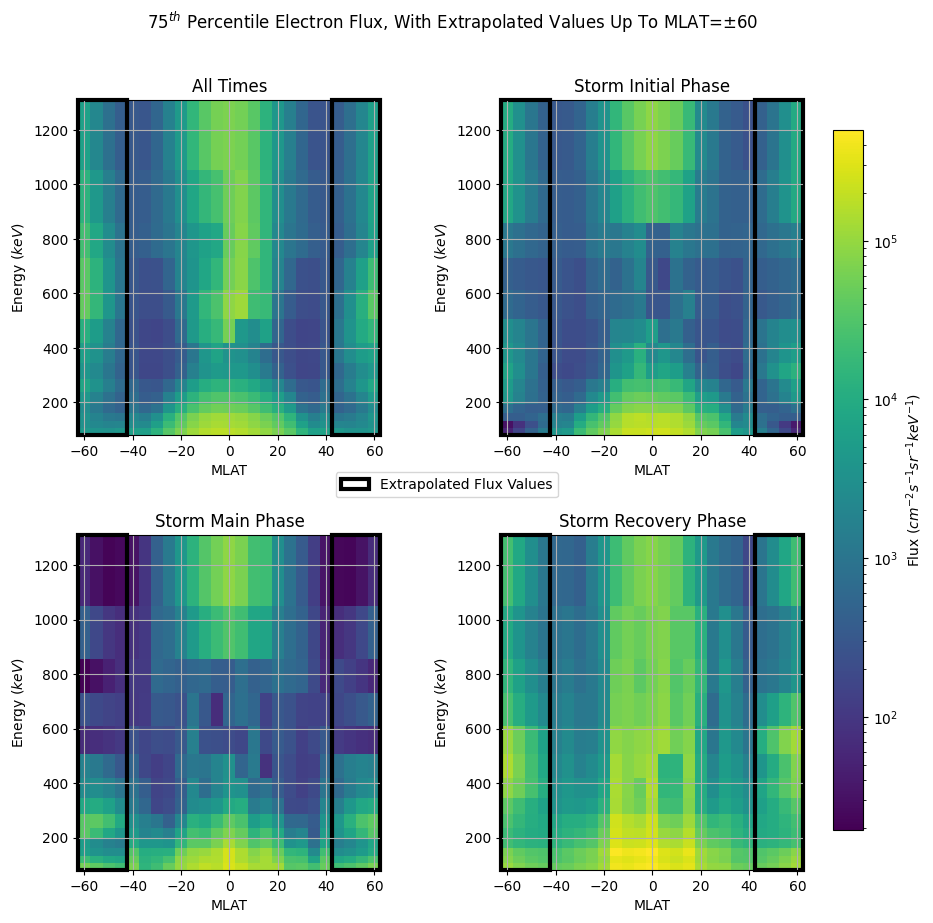

In [100]:
mins=[np.nanmin(All_extrapolated),np.nanmin(Initial_extrapolated),np.nanmin(Main_extrapolated),np.nanmin(Recovery_extrapolated)]
maxs=[np.nanmax(All_extrapolated),np.nanmax(Initial_extrapolated),np.nanmax(Main_extrapolated),np.nanmax(Recovery_extrapolated)]
cmap=colormaps['viridis']
cmap.set_under('white')
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(10,10))
plt.subplots_adjust(wspace=0.4,hspace=0.3)

im=axs[0,0].pcolormesh(extrapolated_mlats,energy_list,All_extrapolated,cmap=cmap,norm=colors.LogNorm(vmin=np.nanmin(mins), vmax=np.nanmax(maxs)))
im=axs[0,1].pcolormesh(extrapolated_mlats,energy_list,Initial_extrapolated,cmap=cmap,norm=colors.LogNorm(vmin=np.nanmin(mins), vmax=np.nanmax(maxs)))
im=axs[1,0].pcolormesh(extrapolated_mlats,energy_list,Main_extrapolated,cmap=cmap,norm=colors.LogNorm(vmin=np.nanmin(mins), vmax=np.nanmax(maxs)))
im=axs[1,1].pcolormesh(extrapolated_mlats,energy_list,Recovery_extrapolated,cmap=cmap,norm=colors.LogNorm(vmin=np.nanmin(mins), vmax=np.nanmax(maxs)))

axs[0,0].set_title('All Times')
axs[1,1].set_title('Storm Recovery Phase')
axs[1,0].set_title('Storm Main Phase')
axs[0,1].set_title('Storm Initial Phase')

for ax in fig.axes:
    ax.set_xlabel('MLAT')
    ax.set_ylabel(r'Energy ($keV$)')
    ax.grid()
    left_rect = patches.Rectangle(
        (0, 0),      # bottom-left corner in axes coords
        0.16,         # width in axes coords
        1,        # height in axes coords
        linewidth=3,
        edgecolor='black',
        facecolor='none',  # transparent fill
        transform=ax.transAxes,
        clip_on=False      # allows drawing outside axes if needed
        )

    right_rect = patches.Rectangle(
        (1-0.16, 0),      # bottom-left corner in axes coords
        0.16,         # width in axes coords
        1,        # height in axes coords
        linewidth=3,
        edgecolor='black',
        facecolor='none',  # transparent fill
        transform=ax.transAxes,
        clip_on=False      # allows drawing outside axes if needed
        )
    ax.set_ylim(ax.get_ylim()[0],ax.get_ylim()[1])
    ax.add_patch(left_rect)
    ax.add_patch(right_rect)
patch=[patches.Rectangle(
        (1-0.16, 0),      # bottom-left corner in axes coords
        0.16,         # width in axes coords
        1,        # height in axes coords
        linewidth=3,
        edgecolor='black',
        facecolor='none',  # transparent fill
        label='Extrapolated Flux Values')]
axs[1,1].legend(loc='center',handles=patch,bbox_to_anchor=(-0.18,1.15))

fig.subplots_adjust(right=0.85)
cbar_ax = fig.add_axes([0.88, 0.15, 0.03, 0.7])  # [left, bottom, width, height]
fig.colorbar(im, cax=cbar_ax,label=r'Flux ($cm^{-2}s^{-1}sr^{-1}keV^{-1}$)')
fig.suptitle(r'$75^{th}$ Percentile Electron Flux, With Extrapolated Values Up To MLAT=$\pm$60 ',y=0.97)